In [1]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45
from scipy.optimize import direct, Bounds
import time

#Symbols
x, y, z, dx, dy, dz, phi, theta, psi, m, gx, gy, T, P, alpha, S, Cl, Cd, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, dphi, dtheta, dpsi = smp.symbols(
'x y z \\dot{x} \\dot{y} \\dot{z} phi theta psi m gamma_x gamma_y T P alpha S C_L C_D I_{xx} I_{yy} I_{zz} \\dot{I_{xx}}, \\dot{I_{yy}}, \\dot{I_{zz}} \\dot{\\phi}, \\dot{\\theta}, \\dot{\\psi}', cls=smp.Function)
t, g, rho, dCoP, dNoz = smp.symbols('t g rho d_{CoP} d_{Noz}')

In [2]:
#Rotation Matrices (DCM)
def Rx(phi):
    return  smp.Matrix([[1,             0,              0],
                        [0, smp.cos(phi), -smp.sin(phi)],
                        [0, smp.sin(phi),  smp.cos(phi)]])
def Ry(theta):
    return  smp.Matrix([[ smp.cos(theta), 0,  smp.sin(theta)],
                        [             0, 1,              0],
                        [-smp.sin(theta), 0,  smp.cos(theta)]])
def Rz(psi):
    return  smp.Matrix([[smp.cos(psi), -smp.sin(psi), 0],
                        [smp.sin(psi),  smp.cos(psi), 0],
                        [0,             0,              1]])
Rbe = Rz(psi(t))*Ry(theta(t))*Rx(phi(t))
Reb=Rbe.T

In [3]:
#Forces

#Gravity
z = smp.Matrix([0,0,1])
Fg = -m(t)*g*z

#Thrust
FtHat = Rbe*Ry(gy(t))*Rx(gx(t))*z
Ft = FtHat*T(t)*P(t)

#Lift (Approximately zero)
v = smp.Matrix([dx(t), dy(t), dz(t)])
Fl=smp.zeros(3,1)
'''
#Actual Expression
LHat = (v.cross(Rbe*z)).cross(v)/ (v.dot(v)*smp.sin(alpha(t)))
L = smp.Rational(1/2)*rho*v.dot(v)*S(alpha(t))*Cl(alpha(t))
Fl = LHat * L
'''

#Drag
D = -smp.Rational(1/2)*rho*v.dot(v)*S(alpha(t))*Cd(alpha(t))
DHat = v / smp.sqrt(v.dot(v))
Fd = DHat*D

#Total force
F = Fg + Ft + Fl + Fd

#Acceleration
a = F / m(t)
a.simplify()
a

Matrix([
[ (-rho*sqrt(\dot{x}(t)**2 + \dot{y}(t)**2 + \dot{z}(t)**2)*C_D(alpha(t))*S(alpha(t))*\dot{x}(t)/2 + (((sin(phi(t))*sin(psi(t)) + sin(theta(t))*cos(phi(t))*cos(psi(t)))*cos(gamma_y(t)) + sin(gamma_y(t))*cos(psi(t))*cos(theta(t)))*cos(gamma_x(t)) - (sin(phi(t))*sin(theta(t))*cos(psi(t)) - sin(psi(t))*cos(phi(t)))*sin(gamma_x(t)))*P(t)*T(t))/m(t)],
[(-rho*sqrt(\dot{x}(t)**2 + \dot{y}(t)**2 + \dot{z}(t)**2)*C_D(alpha(t))*S(alpha(t))*\dot{y}(t)/2 + ((-(sin(phi(t))*cos(psi(t)) - sin(psi(t))*sin(theta(t))*cos(phi(t)))*cos(gamma_y(t)) + sin(gamma_y(t))*sin(psi(t))*cos(theta(t)))*cos(gamma_x(t)) - (sin(phi(t))*sin(psi(t))*sin(theta(t)) + cos(phi(t))*cos(psi(t)))*sin(gamma_x(t)))*P(t)*T(t))/m(t)],
[                                                                                   (-g*m(t) - rho*sqrt(\dot{x}(t)**2 + \dot{y}(t)**2 + \dot{z}(t)**2)*C_D(alpha(t))*S(alpha(t))*\dot{z}(t)/2 + (-(sin(gamma_y(t))*sin(theta(t)) - cos(gamma_y(t))*cos(phi(t))*cos(theta(t)))*cos(gamma_x(t)) - sin(g

In [4]:
#Moment equations

#Body to Euler rate matrix
J = smp.Matrix([[1, smp.sin(phi(t))*smp.tan(theta(t)), smp.cos(phi(t))*smp.tan(theta(t))],
                [0,smp.cos(phi(t)), -smp.sin(phi(t))],
                [0, smp.sin(phi(t)) / smp.cos(theta(t)), smp.cos(phi(t)) / smp.cos(theta(t))]])

#Angular rates
av = smp.Matrix([dphi(t), dtheta(t), dpsi(t)])
omega = J.inv()* av
omega.simplify()

#Inertia matrix and rate
I = smp.diag(Ixx(t),Iyy(t),Izz(t))
dI = smp.diag(dIxx(t),dIyy(t),dIzz(t))

#Total moment (body)
M = (-dNoz*z).cross(Reb*Ft) + (-dCoP*z).cross(Reb*(Fl+Fd))
M.simplify()

#Angular acceleration (aa = [ddphi, ddtheta, ddpsi])
aa = J * I.inv() * (M - dI * omega - omega.cross(I * omega)) + J.diff(t).subs([(phi(t).diff(t),dphi(t)), (theta(t).diff(t),dtheta(t)), (psi(t).diff(t),dpsi(t))]) * omega
aa.simplify()
aa

Matrix([
[((\dot{\phi}(t)*tan(theta(t)) + \dot{\psi}(t)/cos(theta(t)))*I_{xx}(t)*I_{yy}(t)*I_{zz}(t)*\dot{\theta}(t) - (-(\dot{\psi}(t)*sin(phi(t))*cos(theta(t)) + \dot{\theta}(t)*cos(phi(t)))*(\dot{\phi}(t) - \dot{\psi}(t)*sin(theta(t)))*I_{xx}(t) + (\dot{\psi}(t)*sin(phi(t))*cos(theta(t)) + \dot{\theta}(t)*cos(phi(t)))*(\dot{\phi}(t) - \dot{\psi}(t)*sin(theta(t)))*I_{yy}(t) + (\dot{\psi}(t)*cos(phi(t))*cos(theta(t)) - \dot{\theta}(t)*sin(phi(t)))*\dot{I_{zz}}(t))*I_{xx}(t)*I_{yy}(t)*cos(phi(t))*tan(theta(t)) + (-d_{CoP}*rho*((sin(phi(t))*sin(psi(t))*sin(theta(t)) + cos(phi(t))*cos(psi(t)))*\dot{y}(t) + (sin(phi(t))*sin(theta(t))*cos(psi(t)) - sin(psi(t))*cos(phi(t)))*\dot{x}(t) + \dot{z}(t)*sin(phi(t))*cos(theta(t)))*sqrt(\dot{x}(t)**2 + \dot{y}(t)**2 + \dot{z}(t)**2)*C_D(alpha(t))*S(alpha(t)) - 2*d_{Noz}*P(t)*T(t)*sin(gamma_x(t)) + 2*(\dot{\psi}(t)*sin(phi(t))*cos(theta(t)) + \dot{\theta}(t)*cos(phi(t)))*(\dot{\psi}(t)*cos(phi(t))*cos(theta(t)) - \dot{\theta}(t)*sin(phi(t)))*I_{yy}(

In [5]:
#Total state Equation
State = smp.Matrix([v, a, av, aa])
State

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [6]:
#Sub in simpler expressions for functions and variables
State = State.subs([(dx(t), smp.Symbol('dx')), (dy(t), smp.Symbol('dy')), (dz(t), smp.Symbol('dz')), 
                    (phi(t), smp.Symbol('phi')), (theta(t), smp.Symbol('theta')), (psi(t), smp.Symbol('psi')), 
                    (dphi(t), smp.Symbol('dphi')), (dtheta(t), smp.Symbol('dtheta')), (dpsi(t), smp.Symbol('dpsi')), 
                    (gx(t), smp.Symbol('gx')), (gy(t), smp.Symbol('gy')), (P(t), smp.Symbol('P')), 
                    (Cd(alpha(t)), smp.Symbol('Cd')), (Cl(alpha(t)), smp.Symbol('Cl')), (S(alpha(t)), smp.Symbol('S')), 
                    (Ixx(t), smp.Symbol('Ixx')), (Iyy(t), smp.Symbol('Iyy')), (Izz(t), smp.Symbol('Izz')), 
                    (dIxx(t), smp.Symbol('dIxx')), (dIyy(t), smp.Symbol('dIyy')), (dIzz(t), smp.Symbol('dIzz')),
                    (T(t), smp.Symbol('T')), (m(t), smp.Symbol('m')), (dCoP, smp.Symbol('dCoP')), (dNoz, smp.Symbol('dNoz')) ])

In [7]:
#Convert state to numpy array
Statenp = smp.matrix2numpy(State)
Statenp

array([[dx],
       [dy],
       [dz],
       [(-Cd*S*dx*rho*sqrt(dx**2 + dy**2 + dz**2)/2 + P*T*(((sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))*cos(gy) + sin(gy)*cos(psi)*cos(theta))*cos(gx) - (sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi))*sin(gx)))/m],
       [(-Cd*S*dy*rho*sqrt(dx**2 + dy**2 + dz**2)/2 + P*T*((-(sin(phi)*cos(psi) - sin(psi)*sin(theta)*cos(phi))*cos(gy) + sin(gy)*sin(psi)*cos(theta))*cos(gx) - (sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi))*sin(gx)))/m],
       [(-Cd*S*dz*rho*sqrt(dx**2 + dy**2 + dz**2)/2 + P*T*(-(sin(gy)*sin(theta) - cos(gy)*cos(phi)*cos(theta))*cos(gx) - sin(gx)*sin(phi)*cos(theta)) - g*m)/m],
       [dphi],
       [dtheta],
       [dpsi],
       [(Ixx*Iyy*Izz*dtheta*(dphi*tan(theta) + dpsi/cos(theta)) - Ixx*Iyy*(-Ixx*(dphi - dpsi*sin(theta))*(dpsi*sin(phi)*cos(theta) + dtheta*cos(phi)) + Iyy*(dphi - dpsi*sin(theta))*(dpsi*sin(phi)*cos(theta) + dtheta*cos(phi)) + dIzz*(dpsi*cos(phi)*cos(theta) - dtheta*sin(phi)))*cos(phi)*tan(theta) - I

In [8]:
#Define Equations as functions
f_ddx = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'), 
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[3,0],'numpy')
f_ddy = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[4,0],'numpy')
f_ddz = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[5,0],'numpy')
f_ddphi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[9,0],'numpy')
f_ddtheta = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[10,0],'numpy')
f_ddpsi = smp.lambdify([smp.Symbol('dx'), smp.Symbol('dy'), smp.Symbol('dz'),
                      smp.Symbol('phi'), smp.Symbol('theta'), smp.Symbol('psi'),
                      smp.Symbol('dphi'), smp.Symbol('dtheta'), smp.Symbol('dpsi'),
                      smp.Symbol('gx'), smp.Symbol('gy'), smp.Symbol('P'),
                      smp.Symbol('Cd'), smp.Symbol('Cl'), smp.Symbol('S'),
                      smp.Symbol('Ixx'), smp.Symbol('Iyy'), smp.Symbol('Izz'),
                      smp.Symbol('dIxx'), smp.Symbol('dIyy'), smp.Symbol('dIzz'),
                      smp.Symbol('T'), smp.Symbol('m'), smp.Symbol('g'),
                      smp.Symbol('dCoP'), smp.Symbol('dNoz'), smp.Symbol('rho')],Statenp[11,0],'numpy')
f_ddx

<function _lambdifygenerated(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)>

In [9]:
#DiffEq Solver (RK45)

#Constants
gx = 0
gy = 0
P = 1

Cd = 0.1
Cl = 0.01
S = 0.01

Ixx = 0.1705
Iyy = 0.1705
Izz = 0.0024

dIxx = -0.001
dIyy = -0.001
dIzz = -0.00001

T = 100
m = 7
g = 9.8
dCoP = 0.5
dNoz = 0.7
rho = 1.225

# Define the system of ODEs
def system(t, State):
    x, y, z, dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi = State

    global Sphi 
    global Stheta
    Sphi+= phi*dt
    Stheta+= theta*dt

    global Kp
    global Ki
    global Kd
    gx = Kp*phi + Ki*Sphi + Kd*dphi
    gy = Kp*theta + Ki*Stheta + Kd*dtheta

    ddx = f_ddx(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddy = f_ddy(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddz = f_ddz(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddphi = f_ddphi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddtheta = f_ddtheta(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    ddpsi = f_ddpsi(dx, dy, dz, phi, theta, psi, dphi, dtheta, dpsi, gx, gy, P, Cd, Cl, S, Ixx, Iyy, Izz, dIxx, dIyy, dIzz, T, m, g, dCoP, dNoz, rho)
    return [dx, dy, dz, ddx, ddy, ddz, dphi, dtheta, dpsi, ddphi, ddtheta, ddpsi]

# Initial conditions
State0 = [0,0,0,0,0,0,0,0,0,3,3,0]

# Time span
t_span = (0, 20)
t_eval = np.linspace(t_span[0], t_span[1], 500)
dt = (t_span[1]-t_span[0]) / len(t_eval)

#PID Coeffs
Kp = 0.92592593
Ki = 0.0308642
Kd = 0.09259259

#PID Integral
Sphi= 0
Stheta = 0

# Solve the system
sol = solve_ivp(system, t_span, State0, t_eval=t_eval, method='RK45')

In [10]:
#DIRECT search for PID Coeffs

#Function takes in PID Coefficients (Kp, Ki, Kd) and returns the negative of the final height
def FinalHeight(K):
    global Kp
    global Ki
    global Kd
    Kp, Ki, Kd = K

    t_vals, State_vals = [], []
    DidNotFinish = False
    Crashed = False
    start_time = time.time()
    solver = RK45(system, t_span[0], State0, t_span[1])

    while solver.status == "running":
        solver.step()
        t_vals.append(solver.t)
        State_vals.append(solver.y.copy())
                
        if time.time() - start_time > 1.0:   
            solver.status = "stopped"       
            DidNotFinish = True
            break
        if (State_vals[-1][2] < 0):
            solver.status = "stopped"       
            Crashed = True
            break

    if (not (Crashed or DidNotFinish)):
        State_vals = np.array(State_vals).T
        Height = State_vals[2][-1]
    else:
        Height = 0

    global Sphi
    global Stheta
    Sphi= 0
    Stheta = 0
    return -Height


#DIRECT global optimization algorithm to find minimum of -height function (max height given PID coeffs)
#Commented because it can take 20 to 30 minutes

'''
bounds = Bounds([0, 0, 0], [10, 5, 5])
result = direct(FinalHeight, bounds)
result.x, result.fun, result.nfev
'''


'\nbounds = Bounds([0, 0, 0], [10, 5, 5])\nresult = direct(FinalHeight, bounds)\nresult.x, result.fun, result.nfev\n'

Final Height: 874.0068654188235 m


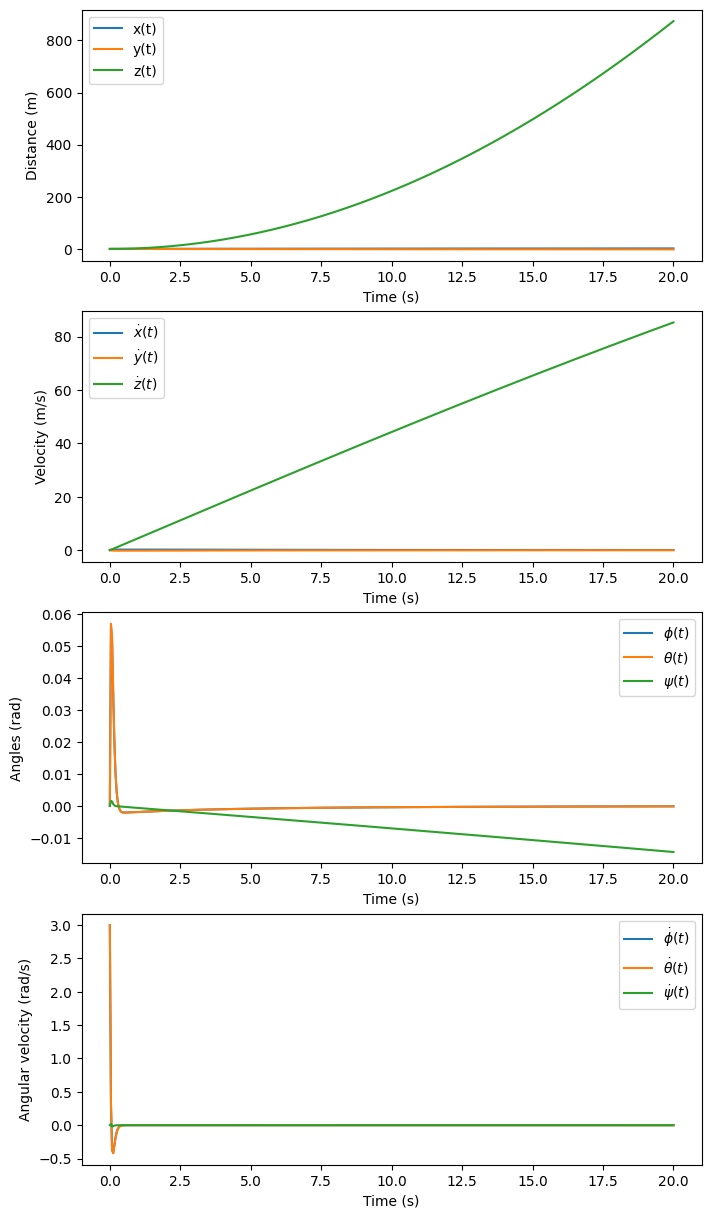

In [11]:
#Plot the trajectory data
fig, ax = plt.subplots(nrows=4, ncols=1,figsize=(8, 15))
labels = ['x(t)', 'y(t)', 'z(t)', r'$\dot{x}(t)$', r'$\dot{y}(t)$', r'$\dot{z}(t)$', r'$\phi(t)$', r'$\theta(t)$', r'$\psi(t)$', r'$\dot{\phi}(t)$', r'$\dot{\theta}(t)$', r'$\dot{\psi}(t)$']
for i in range(4):
    ax[i].plot(sol.t, sol.y[3*i], label = labels[3*i])
    ax[i].plot(sol.t, sol.y[3*i+1], label = labels[3*i+1])
    ax[i].plot(sol.t, sol.y[3*i+2], label = labels[3*i+2])
    ax[i].set_xlabel("Time (s)")
    ax[i].legend()
ax[0].set_ylabel("Distance (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[2].set_ylabel("Angles (rad)")
ax[3].set_ylabel("Angular velocity (rad/s)")

print(f'Final Height: {sol.y[2][-1]} m')
plt.show()

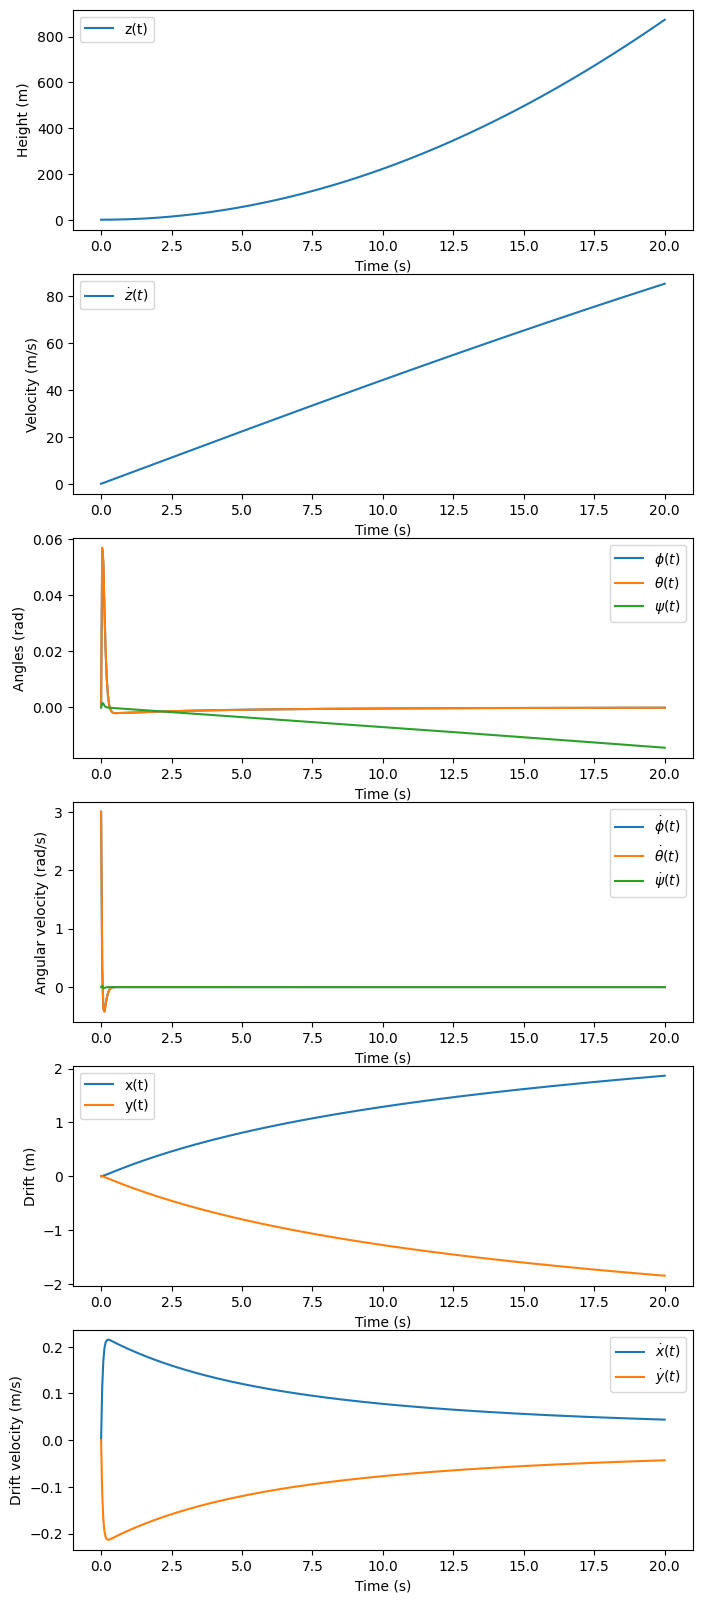

In [12]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6, ncols=1,figsize=(8, 20))
labels = ['x(t)', 'y(t)', 'z(t)', r'$\dot{x}(t)$', r'$\dot{y}(t)$', r'$\dot{z}(t)$', r'$\phi(t)$', r'$\theta(t)$', r'$\psi(t)$', r'$\dot{\phi}(t)$', r'$\dot{\theta}(t)$', r'$\dot{\psi}(t)$']

ax[0].set_ylabel("Height (m)")
ax[0].plot(sol.t, sol.y[2], label = labels[2])

ax[1].set_ylabel("Velocity (m/s)")
ax[1].plot(sol.t, sol.y[5], label = labels[5])

ax[2].set_ylabel("Angles (rad)")
ax[2].plot(sol.t, sol.y[6], label = labels[6])
ax[2].plot(sol.t, sol.y[7], label = labels[7])
ax[2].plot(sol.t, sol.y[8], label = labels[8])

ax[3].set_ylabel("Angular velocity (rad/s)")
ax[3].plot(sol.t, sol.y[9], label = labels[9])
ax[3].plot(sol.t, sol.y[10], label = labels[10])
ax[3].plot(sol.t, sol.y[11], label = labels[11])

ax[4].set_ylabel("Drift (m)")
ax[4].plot(sol.t, sol.y[0], label = labels[0])
ax[4].plot(sol.t, sol.y[1], label = labels[1])

ax[5].set_ylabel("Drift velocity (m/s)")
ax[5].plot(sol.t, sol.y[3], label = labels[3])
ax[5].plot(sol.t, sol.y[4], label = labels[4])

for i in range(6):
    ax[i].set_xlabel("Time (s)")
    ax[i].legend()

#Show plots
plt.show()